# Weight Averaging and Plateau Stopping

With `ema_horizon_epochs` set, the `Trainer` keeps an average of the trainable weights next to the live iterate.
Every applied optimizer step moves it toward the new iterate,

$$\bar w_{t+1} = \bar w_t + \alpha_t \left(w_{t+1} - \bar w_t\right), \qquad \alpha_t = \max\left(\frac{1}{H}, \frac{1}{t + 2}\right),$$

where $t$ counts the steps applied so far and $H$ is the horizon in steps, `ema_horizon_epochs` times the batches per epoch.
Up to $H$ iterates the average is their exact running mean, the initial weights included (Polyak-Ruppert averaging).
After that it is an exponential moving average over about the last $H$ steps.

The optimizer never sees the average, it keeps stepping from the live iterate.
The average is the model that is validated, ranked, checkpointed, restored and tested (`Trainer.eval_model`).
Early stopping then watches the averaged validation loss,
and `min_relative_improvement` makes it count only a gain larger than that fraction of the best loss.

This notebook trains a two-parameter model, so both the iterate and the average can be drawn on the loss landscape.

In [1]:
import os

# Each Trainer.train call opens a progress bar, and this notebook calls it once per epoch
os.environ["TQDM_DISABLE"] = "1"

import tempfile

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import xarray as xr
from absl import logging as absl_logging
from loguru import logger

from popsim.ml.dataloading import make_time_indep_dataloader
from popsim.ml.eval import make_val_loss_eval_fn
from popsim.ml.loggers import NullLogger
from popsim.ml.trainer import EarlyStopping, Trainer

logger.disable("popsim")
# Orbax warns on every checkpoint of an optimizer without state, like plain SGD
absl_logging.set_verbosity(absl_logging.ERROR)

ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/home/zkeith/proj/popsim_dirs/popsim_transport_predictor2/.venv/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 496, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/zkeith/proj/popsim_dirs/popsim_transport_predictor2/.venv/lib/python3.12/site-packages/jax_plugins/xla_cuda13/__init__.py", line 369, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/home/zkeith/proj/popsim_dirs/popsim_transport_predictor2/.venv/lib/python3.12/site-packages/jax_plugins/xla_cuda13/__init__.py", line 273, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


## A narrow valley

The model is a linear regression with two weights, $y = w_1 x_1 + w_2 x_2$, fit to noisy targets.
The two inputs are 90 percent correlated, so the mean squared error is a long, narrow diagonal valley:
its curvature across the valley is 19 times its curvature along it.
Each minibatch sees different noise, so its gradient points a little off the true one.
At a constant learning rate SGD therefore keeps rattling around the optimum instead of settling on it,
which is exactly the noise an average of the iterates removes.

In [2]:
rng = np.random.default_rng(0)
w_true = np.array([1.0, -0.5])
input_cov = np.array([[1.0, 0.9], [0.9, 1.0]])
noise_std = 1.0


def _regression_dataset(n_samples: int) -> xr.Dataset:
    # One episode whose time slices are the samples, the layout make_time_indep_dataloader expects
    x = rng.multivariate_normal(np.zeros(2), input_cov, n_samples)
    y = x @ w_true + noise_std * rng.normal(size=n_samples)
    dims = ("episode", "time")
    return xr.Dataset(
        {"x1": (dims, x[None, :, 0]), "x2": (dims, x[None, :, 1]), "y": (dims, y[None, :])},
        coords={"episode": [0], "time": np.arange(n_samples, dtype=float)},
    )


ds_train = _regression_dataset(256)
ds_val = _regression_dataset(256)
ds_test = _regression_dataset(4096)

loader_kwargs = dict(time_coord="time", episode_coord="episode", input_vars=["x1", "x2"], target_vars=["y"])


def _shuffled_train_dl(shuffle_seed: int):
    # 16 steps per epoch, the key seeds the shuffle of every epoch
    shuffled_dl = make_time_indep_dataloader(ds_train, batch_size=16, shuffle=True, **loader_kwargs)
    shuffled_dl.key = jax.random.key(shuffle_seed)
    return shuffled_dl


train_dl = _shuffled_train_dl(shuffle_seed=0)
val_dl = make_time_indep_dataloader(ds_val, batch_size=None, shuffle=False, **loader_kwargs)
test_dl = make_time_indep_dataloader(ds_test, batch_size=None, shuffle=False, **loader_kwargs)


class LinearModel2D(eqx.Module):
    w: jax.Array

    def __call__(self, inputs):
        return {"y": self.w[0] * inputs["x1"] + self.w[1] * inputs["x2"]}


def squared_error(prediction, target):
    return jnp.square(prediction["y"] - target["y"])

The model is linear, so the loss of any weights on any of the three sets has a closed form.
That gives the landscape below and the optimum of the training loss, the point every run should approach.
The targets carry noise of unit variance, so every loss sits on a floor near 1.
The plots therefore show the excess validation loss, the validation loss less the lowest any weights can reach on the validation set.

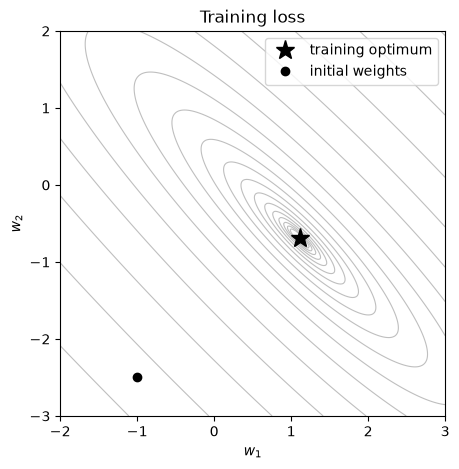

In [3]:
def _features_and_targets(ds: xr.Dataset) -> tuple[np.ndarray, np.ndarray]:
    features = np.stack([ds["x1"].values[0], ds["x2"].values[0]], axis=1)
    targets = ds["y"].values[0]
    return features, targets


def _mean_squared_error(w: np.ndarray, ds: xr.Dataset) -> np.ndarray:
    # w holds weight pairs in its last axis, any leading shape
    features, targets = _features_and_targets(ds)
    residuals = w @ features.T - targets
    return np.mean(np.square(residuals), axis=-1)


features_train, targets_train = _features_and_targets(ds_train)
w_optimum, *_ = np.linalg.lstsq(features_train, targets_train, rcond=None)
features_val, targets_val = _features_and_targets(ds_val)
w_val_optimum, *_ = np.linalg.lstsq(features_val, targets_val, rcond=None)
w_init = jnp.array([-1.0, -2.5])

w1_grid, w2_grid = np.meshgrid(np.linspace(-2.0, 3.0, 251), np.linspace(-3.0, 2.0, 251))
w_grid = np.stack([w1_grid, w2_grid], axis=-1)
loss_grid_train = _mean_squared_error(w_grid, ds_train)
loss_levels = np.min(loss_grid_train) + np.geomspace(0.003, 20.0, 18)


def _plot_landscape(ax, w1_lim=(-2.0, 3.0), w2_lim=(-3.0, 2.0)):
    ax.contour(w1_grid, w2_grid, loss_grid_train, levels=loss_levels, colors="0.75", linewidths=0.8)
    ax.plot(*w_optimum, marker="*", markersize=14, color="k", linestyle="none", label="training optimum")
    ax.set_xlim(w1_lim)
    ax.set_ylim(w2_lim)
    ax.set_xlabel("$w_1$")
    ax.set_ylabel("$w_2$")
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(5, 5))
_plot_landscape(ax)
ax.plot(*w_init, marker="o", color="k", linestyle="none", label="initial weights")
ax.set_title("Training loss")
ax.legend(loc="upper right")
plt.show()

## Averaging never changes the iterate

`Trainer.train` trains up to `max_epochs` epochs in total,
so calling it with one more epoch each time trains one epoch per call on exactly the code path a full run takes.
After every epoch we record the live iterate (`trainer.train_state.model`) and the averaged model (`trainer.eval_model`).

The learning rate is constant, and the horizon is 5 epochs (80 steps).
Both runs start from the same weights and draw the same batches, since every epoch's shuffle is keyed by the epoch number.
The iterate of the averaging run is identical to that of the plain run: averaging only changes which model is evaluated.

In [4]:
LEARNING_RATE = 0.2
N_EPOCHS = 150


def _make_trainer(ema_horizon_epochs: float | None, checkpoint_dir: str | None = None) -> Trainer:
    return Trainer(
        model=LinearModel2D(w=w_init),
        loss_fn=squared_error,
        optimizer=optax.sgd(LEARNING_RATE),
        checkpoint_dir=checkpoint_dir,
        ema_horizon_epochs=ema_horizon_epochs,
    )


def _per_epoch_weights(ema_horizon_epochs: float | None, shuffled_dl=train_dl) -> tuple[np.ndarray, np.ndarray]:
    # Row 0 holds the initial weights, row n the weights after n epochs
    trainer = _make_trainer(ema_horizon_epochs)
    w_raw = [np.asarray(trainer.train_state.model.w)]
    w_averaged = [np.asarray(trainer.eval_model.w)]
    for n_epochs in range(1, N_EPOCHS + 1):
        trainer.train(shuffled_dl, max_epochs=n_epochs, logger=NullLogger())
        w_raw.append(np.asarray(trainer.train_state.model.w))
        w_averaged.append(np.asarray(trainer.eval_model.w))
    return np.stack(w_raw), np.stack(w_averaged)


w_raw_plain, _ = _per_epoch_weights(ema_horizon_epochs=None)
w_raw, w_averaged = _per_epoch_weights(ema_horizon_epochs=5.0)
print("Iterates of the plain and the averaging run identical:", np.array_equal(w_raw_plain, w_raw))

Iterates of the plain and the averaging run identical: True


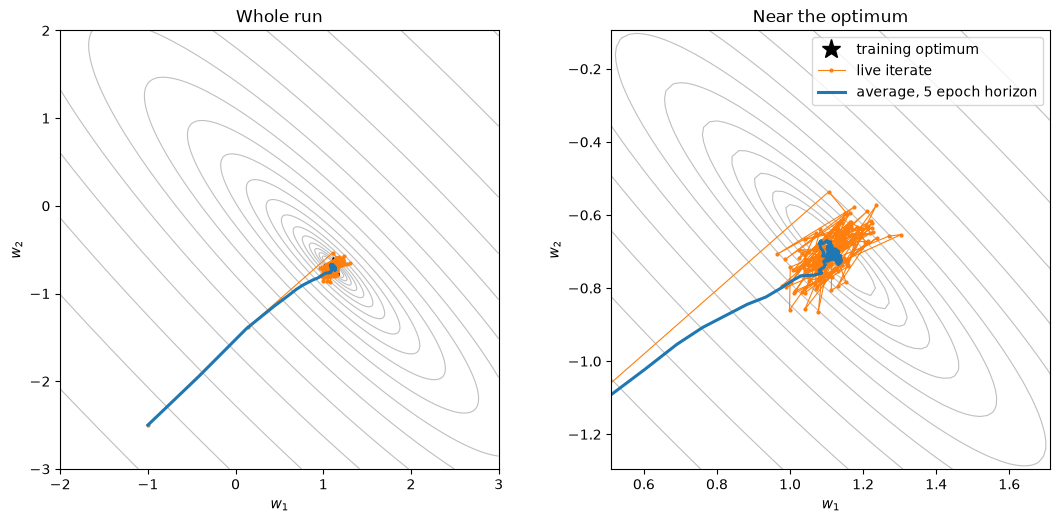

In [5]:
zoom_w1 = (w_optimum[0] - 0.6, w_optimum[0] + 0.6)
zoom_w2 = (w_optimum[1] - 0.6, w_optimum[1] + 0.6)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (w1_lim, w2_lim), title in [
    (axes[0], ((-2.0, 3.0), (-3.0, 2.0)), "Whole run"),
    (axes[1], (zoom_w1, zoom_w2), "Near the optimum"),
]:
    _plot_landscape(ax, w1_lim, w2_lim)
    ax.plot(w_raw[:, 0], w_raw[:, 1], color="tab:orange", marker=".", markersize=4, linewidth=0.8, label="live iterate")
    ax.plot(w_averaged[:, 0], w_averaged[:, 1], color="tab:blue", linewidth=2.2, label="average, 5 epoch horizon")
    ax.set_title(title)
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

The iterate crosses the steep valley wall within the first epoch.
The average takes about 10 epochs, since its warm-up weighs the initial weights and every early iterate alike.
That lag is the price of averaging.
Near the optimum the iterate keeps jumping around while the average sits close to the optimum.
The validation loss shows the same: the iterate's curve stays noisy for the whole run, the average's is smooth and lower.
Picking the epoch with the lowest raw validation loss picks the iterate that happened to land well on the validation set,
a choice that flips with the noise.

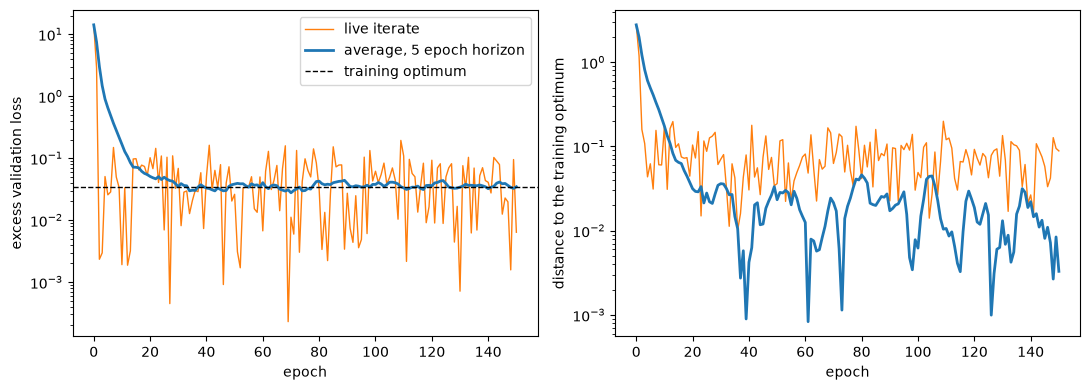

In [6]:
epochs = np.arange(N_EPOCHS + 1)
val_loss_floor = _mean_squared_error(w_val_optimum, ds_val)
val_loss_raw = _mean_squared_error(w_raw, ds_val)
val_loss_averaged = _mean_squared_error(w_averaged, ds_val)
val_loss_at_optimum = _mean_squared_error(w_optimum, ds_val)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, val_loss_raw - val_loss_floor, color="tab:orange", linewidth=1.0, label="live iterate")
axes[0].plot(epochs, val_loss_averaged - val_loss_floor, color="tab:blue", linewidth=2.0, label="average, 5 epoch horizon")
axes[0].axhline(val_loss_at_optimum - val_loss_floor, color="k", linestyle="--", linewidth=1.0, label="training optimum")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("excess validation loss")
axes[0].legend()

distance_raw = np.linalg.norm(w_raw - w_optimum, axis=1)
distance_averaged = np.linalg.norm(w_averaged - w_optimum, axis=1)
axes[1].plot(epochs, distance_raw, color="tab:orange", linewidth=1.0, label="live iterate")
axes[1].plot(epochs, distance_averaged, color="tab:blue", linewidth=2.0, label="average, 5 epoch horizon")
axes[1].set_yscale("log")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("distance to the training optimum")
plt.tight_layout()
plt.show()

## The horizon

A longer horizon averages more iterates, so it removes more noise, but it remembers more of the past.
While the iterate still descends, the average trails behind it,
by half the steps so far during the warm-up and by about one horizon after it.
The warm-up matters at the start: the first $H$ iterates are averaged uniformly, the initial weights among them,
so a long horizon spends its first few epochs dragging the initial weights along.
A horizon of 1 epoch here is 16 steps, already a clear improvement on the raw iterate.

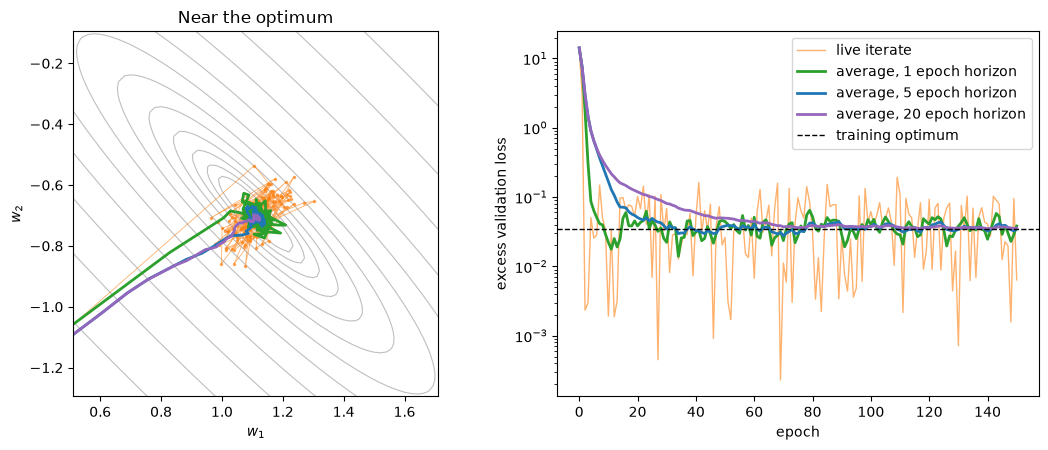

In [7]:
horizons_epochs = [1.0, 5.0, 20.0]
horizon_colors = ["tab:green", "tab:blue", "tab:purple"]
w_averaged_by_horizon = {5.0: w_averaged}
for ema_horizon_epochs in [1.0, 20.0]:
    _, w_averaged_by_horizon[ema_horizon_epochs] = _per_epoch_weights(ema_horizon_epochs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
_plot_landscape(axes[0], zoom_w1, zoom_w2)
axes[0].plot(w_raw[:, 0], w_raw[:, 1], color="tab:orange", marker=".", markersize=3, linewidth=0.6, alpha=0.6, label="live iterate")
axes[1].plot(epochs, val_loss_raw - val_loss_floor, color="tab:orange", linewidth=1.0, alpha=0.6, label="live iterate")
for ema_horizon_epochs, color in zip(horizons_epochs, horizon_colors, strict=True):
    w_path = w_averaged_by_horizon[ema_horizon_epochs]
    label = f"average, {ema_horizon_epochs:g} epoch horizon"
    axes[0].plot(w_path[:, 0], w_path[:, 1], color=color, linewidth=2.0, label=label)
    val_loss_path = _mean_squared_error(w_path, ds_val)
    axes[1].plot(epochs, val_loss_path - val_loss_floor, color=color, linewidth=2.0, label=label)
axes[0].set_title("Near the optimum")
axes[1].axhline(val_loss_at_optimum - val_loss_floor, color="k", linestyle="--", linewidth=1.0, label="training optimum")
axes[1].set_yscale("log")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("excess validation loss")
axes[1].legend()
plt.tight_layout()
plt.show()

## Stopping and selecting on the averaged curve

`EarlyStopping` counts the validations since the last improvement and stops after `patience` of them.
The checkpoint a run restores is the one with the lowest validation loss up to the stop.
On the raw curve any lower value is an improvement, so a lucky dip resets the count and becomes the selected checkpoint,
and which epoch that is depends on where the jitter happened to land.
On the averaged curve the dips are gone,
and `min_relative_improvement` asks for a gain larger than that fraction of the best before resetting the count,
so the run stops once the average has stopped making real progress.

Both rules are replayed below with the same patience on 8 shuffle orders of the same data.
Each order is one averaging run, whose live iterate is exactly that of a plain run.
The test loss is measured on 4096 fresh samples.

In [8]:
PATIENCE = 20
SHUFFLE_SEEDS = range(8)


def _replay_stop_rule(val_losses: np.ndarray, patience: int, min_relative_improvement: float) -> tuple[int, int]:
    # val_losses[n] is the loss after n epochs, validation starts after the first one
    early_stopping = EarlyStopping(patience, min_relative_improvement)
    stop_epoch = len(val_losses) - 1
    for epoch in range(1, len(val_losses)):
        if early_stopping.should_stop(val_losses[epoch]):
            stop_epoch = epoch
            break
    selected_offset = np.argmin(val_losses[1 : stop_epoch + 1])
    selected_epoch = 1 + int(selected_offset)
    return stop_epoch, selected_epoch


rules = {
    "live iterate, any gain counts": 0.0,
    "average, any gain counts": 0.0,
    "average, gains above 1 percent count": 0.01,
}
# Per rule, one (stop epoch, selected weights, val loss, test loss) record per shuffle order
selections = {name: [] for name in rules}
for shuffle_seed in SHUFFLE_SEEDS:
    shuffled_dl = _shuffled_train_dl(shuffle_seed)
    w_raw_path, w_averaged_path = _per_epoch_weights(5.0, shuffled_dl)
    for name, min_relative_improvement in rules.items():
        w_path = w_averaged_path if name.startswith("average") else w_raw_path
        val_losses = _mean_squared_error(w_path, ds_val)
        stop_epoch, selected_epoch = _replay_stop_rule(val_losses, PATIENCE, min_relative_improvement)
        w_selected = w_path[selected_epoch]
        test_loss = _mean_squared_error(w_selected, ds_test)
        selections[name].append((stop_epoch, w_selected, val_losses[selected_epoch], test_loss))

test_loss_at_optimum = _mean_squared_error(w_optimum, ds_test)
print(f"{'rule':38s} {'stop epoch':>12s} {'val loss':>9s} {'test loss':>16s}")
for name, records in selections.items():
    stop_epochs = np.array([record[0] for record in records])
    val_losses_selected = np.array([record[2] for record in records])
    test_losses_selected = np.array([record[3] for record in records])
    stop_summary = f"{stop_epochs.mean():5.1f} +- {stop_epochs.std():4.1f}"
    test_summary = f"{test_losses_selected.mean():.4f} +- {test_losses_selected.std():.4f}"
    print(f"{name:38s} {stop_summary:>12s} {val_losses_selected.mean():9.4f} {test_summary:>16s}")
print(f"{'training optimum':38s} {'':>12s} {val_loss_at_optimum:9.4f} {test_loss_at_optimum:16.4f}")

rule                                     stop epoch  val loss        test loss
live iterate, any gain counts           36.9 +- 11.1    1.0099 1.0125 +- 0.0052
average, any gain counts                69.0 +- 14.8    1.0378 0.9966 +- 0.0004
average, gains above 1 percent count    49.0 +-  5.1    1.0390 0.9970 +- 0.0009
training optimum                                       1.0439           0.9985


The raw rule's selected checkpoints score a lower validation loss than the training optimum itself.
The validation set is a finite sample with an optimum of its own,
and the cloud of jittery iterates is wide enough that its lowest point is the iterate nearest that optimum.
So the raw selection fits the validation set's noise:
its validation loss is optimistic, and its test loss is higher and changes with the shuffle order.
The averaged selections sit next to the training optimum whatever the shuffle order, as the scatter below shows.
The 1 percent tolerance stops those runs earlier at no cost here.
It is relative to the whole validation loss, noise floor included,
so with a floor near 1 and an excess near 0.03 it asks for real progress of about a third of the excess.

Averaging removes the optimizer's jitter, not the validation sample's noise.
The selected checkpoint is still the lowest point of a validation curve,
so a descent path that happens to pass close to the validation optimum can still be selected on the way down.
Starting this model at $w = (3, 0.5)$ does exactly that.

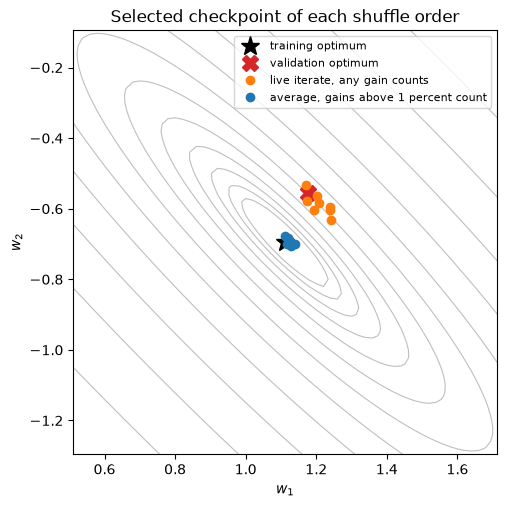

In [9]:
rule_colors = {"live iterate, any gain counts": "tab:orange", "average, gains above 1 percent count": "tab:blue"}
fig, ax = plt.subplots(figsize=(5.5, 5.5))
_plot_landscape(ax, zoom_w1, zoom_w2)
ax.plot(*w_val_optimum, marker="X", markersize=11, color="tab:red", linestyle="none", label="validation optimum")
for name, color in rule_colors.items():
    w_selected = np.stack([record[1] for record in selections[name]])
    ax.plot(w_selected[:, 0], w_selected[:, 1], marker="o", linestyle="none", color=color, label=name)
ax.set_title("Selected checkpoint of each shuffle order")
ax.legend(loc="upper right", fontsize=8)
plt.show()

## End to end

Finally the same comparison through one ordinary `Trainer.train` call each,
with validation every epoch, checkpoints ranked by the validation loss, and the test eval of the restored best checkpoint.
With averaging on, the checkpoint's `model` item is the average, so `restore_model` and every later consumer get the averaged model.

In [10]:
test_eval_suite = {"loss": make_val_loss_eval_fn(squared_error)}
print(f"{'run':40s} {'stop':>5s} {'best':>5s} {'test loss':>10s}")
for name, ema_horizon_epochs, min_relative_improvement in [
    ("live iterate, any gain counts", None, 0.0),
    ("average, gains above 1 percent count", 5.0, 0.01),
]:
    with tempfile.TemporaryDirectory() as checkpoint_dir:
        trainer = _make_trainer(ema_horizon_epochs, checkpoint_dir)
        test_results = trainer.train(
            train_dl,
            val_dl,
            test_dl=test_dl,
            test_eval_suite=test_eval_suite,
            max_epochs=N_EPOCHS,
            patience=PATIENCE,
            min_relative_improvement=min_relative_improvement,
            logger=NullLogger(),
        )
        stop_epoch = trainer.checkpoint_manager.latest_step()
        best_epoch = trainer.checkpoint_manager.best_step()
        test_loss = float(test_results["test/loss"]["mean"])
        trainer.checkpoint_manager.close()
    print(f"{name:40s} {stop_epoch:5d} {best_epoch:5d} {test_loss:10.4f}")

run                                       stop  best  test loss
live iterate, any gain counts               47    27     1.0049
average, gains above 1 percent count        54    43     0.9973
